In [1]:
import numpy as np
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

In [2]:
# Features: [annual income (k$), spending score (1-100)]
X = np.array([
    [15, 80], [18, 85], [20, 75], [22, 90],      # low income, high spending
    [60, 50], [65, 45], [62, 55], [68, 48],      # medium income, medium spending
    [110, 15], [115, 10], [120, 20], [105, 12]   # high income, low spending
])

In [3]:
model = GaussianMixture(n_components=3, random_state=42)
model.fit(X)

,"n_components n_components: int, default=1The number of mixture components.",3
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [4]:
labels = model.predict(X)
print("Cluster Labels:", labels)

Cluster Labels: [2 2 2 2 0 0 0 0 1 1 1 1]


In [5]:
new_customer = np.array([[64, 52]])
prediction = model.predict(new_customer)
probabilities = model.predict_proba(new_customer)[0]

print("New Customer Cluster:", prediction[0])
print("Membership Probabilities:", np.round(probabilities, 3))

New Customer Cluster: 0
Membership Probabilities: [1. 0. 0.]


In [6]:
print("Cluster Centers (means):")
print(np.round(model.means_, 2))
print("Cluster Weights:", np.round(model.weights_, 2))

Cluster Centers (means):
[[ 63.75  49.5 ]
 [112.5   14.25]
 [ 18.75  82.5 ]]
Cluster Weights: [0.33 0.33 0.33]


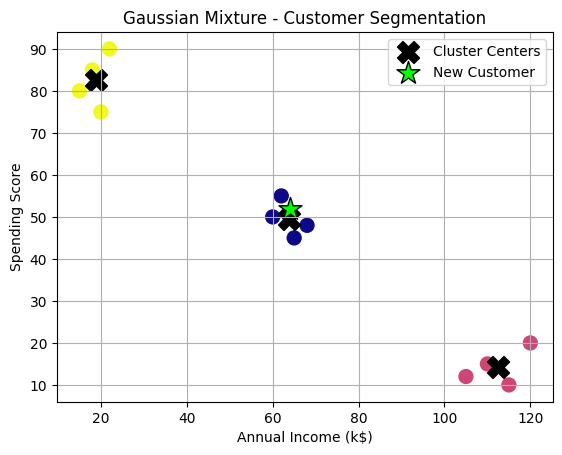

In [7]:
plt.scatter(
    X[:, 0], X[:, 1],
    c=labels,
    cmap="plasma",
    s=100
)

plt.scatter(
    model.means_[:, 0],
    model.means_[:, 1],
    color="black",
    marker="X",
    s=250,
    label="Cluster Centers"
)

plt.scatter(64, 52, color="lime", edgecolor="black", marker="*", s=300, label="New Customer")

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Gaussian Mixture - Customer Segmentation")
plt.legend()
plt.grid(True)
plt.show()